<a href="https://colab.research.google.com/github/gurnisha-rehal/group3-blink-detector/blob/main/blink_detector_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group 3 Blink Detection - Computer Vision Project

## Cloning YOLO

### Connect Google Drive

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Importing** required Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import glob
import json
import os
import shutil
import zipfile

from PIL import Image
from collections import Counter, defaultdict

In [6]:
%cd "/content/drive/MyDrive/Colab Notebooks"
!ls

/content/drive/MyDrive/Colab Notebooks
blink_detector_training.ipynb  ultralytics	Untitled1.ipynb  yolov8s.pt
runs			       Untitled0.ipynb	yolov8n.pt	 zidane.jpg


### Install YOLOv8

In [7]:
!pip install ultralytics

import ultralytics
ultralytics.checks()

from ultralytics import YOLO

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [8]:
!git clone https://github.com/ultralytics/ultralytics.git

fatal: destination path 'ultralytics' already exists and is not an empty directory.


## Data Preprocessing

*Defining* paths to train and test folders.

In [9]:
# Main project directory
project_dir = "/content/drive/MyDrive/IAT360 CV Project/blink-detector"

# Original Roboflow dataset
zip_path = os.path.join(project_dir, "dataset.zip")
source_dir = os.path.join(project_dir, "coco_source")

# Our collected images
our_images_dir = os.path.join(project_dir, "our_images")
our_image_dir = os.path.join(our_images_dir, "images")
our_label_dir = os.path.join(our_images_dir, "labels")

# Final YOLO dataset
output_dir = os.path.join(project_dir, "dataset")

# Image and label directories
image_dir = os.path.join(output_dir, "images")
label_dir = os.path.join(output_dir, "labels")

print("Project directory:", project_dir)
print("Roboflow ZIP exists:", os.path.exists(zip_path))
print("Collected images folder exists:", os.path.exists(our_image_dir))

Project directory: /content/drive/MyDrive/IAT360 CV Project/blink-detector
Roboflow ZIP exists: True
Collected images folder exists: True


### Extracting the Roboflow dataset

In [10]:
# Extract Roboflow dataset

os.makedirs(source_dir, exist_ok=True)
required_splits = ["train", "valid", "test"]
if not all(os.path.isdir(os.path.join(source_dir, split))
           for split in required_splits):

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(source_dir)
    print("Extraction complete")
else:
    print("Roboflow dataset already extracted.")

Roboflow dataset already extracted.


### Defining train and validation directories

In [11]:
# Roboflow training and validation directories

train_dir = os.path.join(source_dir, "train")
valid_dir = os.path.join(source_dir, "valid")

print("Training directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(valid_dir))

Training directory exists: True
Validation directory exists: True


### Fixing directories for YOLO structure

In [12]:
# Create YOLO dataset directories
folders = [
    os.path.join(image_dir, "train"),
    os.path.join(image_dir, "val"),
    os.path.join(label_dir, "train"),
    os.path.join(label_dir, "val")
]

# Clear previously generated folders
for folder in folders:

    if os.path.exists(folder):
        shutil.rmtree(folder)

    os.makedirs(folder, exist_ok=True)

print("YOLO directories created.")

YOLO directories created.


### Convert COCO to YOLO format

In [13]:
category_mapping = {
    "open": 0,
    "closed": 1
}

class_names = {
    0: "Open",
    1: "Closed"
}

### Convert annotations and copy images

In [14]:
def convert_dataset(split_dir, split_name):

    # Load COCO annotations
    annotation_path = os.path.join(
        split_dir, "_annotations.coco.json"
    )

    with open(annotation_path, "r") as f:
        coco_data = json.load(f)

    # Map COCO category IDs to YOLO class IDs
    category_ids = {}

    for category in coco_data["categories"]:
        category_name = category["name"].lower()
        if category_name in category_mapping:
            category_ids[category["id"]] = category_mapping[category_name]

    # Group annotations by image ID
    annotations_by_image = defaultdict(list)

    for annotation in coco_data["annotations"]:
        annotations_by_image[annotation["image_id"]].append(annotation)

    converted_count = Counter()
    image_count = 0
    missing_images = []

    for image in coco_data["images"]:

        image_id = image["id"]
        filename = image["file_name"]
        image_path = os.path.join(split_dir, filename)

        # Check if image exists
        if not os.path.exists(image_path):
            missing_images.append(filename)
            continue

        # Copy image into YOLO directory
        image_name = os.path.splitext(os.path.basename(filename))[0] + ".jpg"

        destination_image = os.path.join(
            image_dir, split_name, image_name
        )

        # Convert image to RGB and save as JPEG
        img = Image.open(image_path).convert("RGB")
        img.save(destination_image, "JPEG")

        # Create corresponding TXT label file
        label_filename = os.path.splitext(image_name)[0] + ".txt"

        label_path = os.path.join(
            label_dir, split_name, label_filename
        )

        labels = []

        for annotation in annotations_by_image.get(image_id, []):
            category_id = annotation["category_id"]

            # Ignore categories outside Open and Closed
            if category_id not in category_ids:
                continue
            x, y, width, height = annotation["bbox"]
            image_width = image["width"]
            image_height = image["height"]

            # Convert COCO coordinates to YOLO coordinates
            x_center = (x + width / 2) / image_width
            y_center = (y + height / 2) / image_height
            normalized_width = width / image_width
            normalized_height = height / image_height
            class_id = category_ids[category_id]
            labels.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{normalized_width:.6f} {normalized_height:.6f}"
            )

            converted_count[class_id] += 1

        # Save TXT annotation file
        with open(label_path, "w") as f:
            f.write("\n".join(labels))

        image_count += 1

    print(f"\n{split_name.upper()} conversion complete")
    print("Images copied:", image_count)
    print("Open annotations:", converted_count[0])
    print("Closed annotations:", converted_count[1])
    print("Missing images:", len(missing_images))

    if missing_images:
        print("Missing image files:", missing_images)

    return image_count

### Convert training and validation datasets

In [15]:
# Convert Roboflow training dataset
train_count = convert_dataset(train_dir, "train")

# Convert Roboflow validation dataset
val_count = convert_dataset(valid_dir, "val")


TRAIN conversion complete
Images copied: 77
Open annotations: 86
Closed annotations: 15
Missing images: 0

VAL conversion complete
Images copied: 9
Open annotations: 11
Closed annotations: 1
Missing images: 0


### Check for missing images and labels

In [16]:
for split in ["train", "val"]:

    images = glob.glob(
        os.path.join(image_dir, split, "*.jpg")
    )

    labels = glob.glob(
        os.path.join(label_dir, split, "*.txt")
    )

    image_names = {
        os.path.splitext(os.path.basename(f))[0]
        for f in images
    }

    label_names = {
        os.path.splitext(os.path.basename(f))[0]
        for f in labels
    }

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    print(f"\n{split.upper()} DATASET")
    print("Total images:", len(images))
    print("Total labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))


TRAIN DATASET
Total images: 77
Total labels: 77
Images without labels: 0
Labels without images: 0

VAL DATASET
Total images: 9
Total labels: 9
Images without labels: 0
Labels without images: 0


### YOLO config file

In [17]:
# Create data.yaml
yaml_content = f"""
path: {output_dir}
train: images/train
val: images/val

nc: 2
names:
  0: Open
  1: Closed
"""

yaml_path = os.path.join(output_dir, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("YOLO configuration file created:", yaml_path)

YOLO configuration file created: /content/drive/MyDrive/IAT360 CV Project/blink-detector/dataset/data.yaml


Visualizing some pictures from the dataset

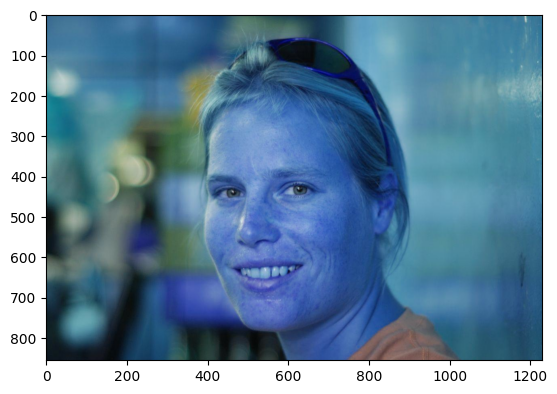

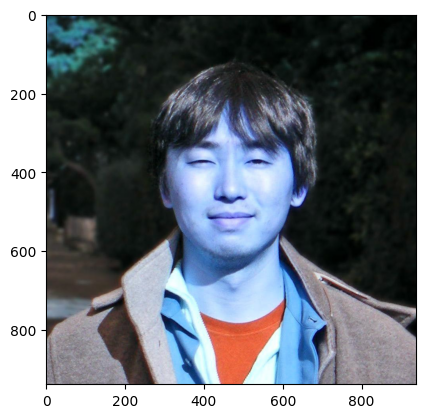

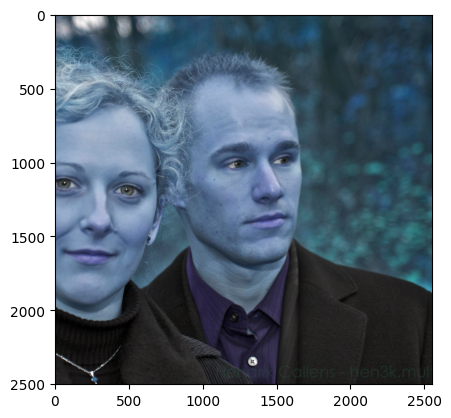

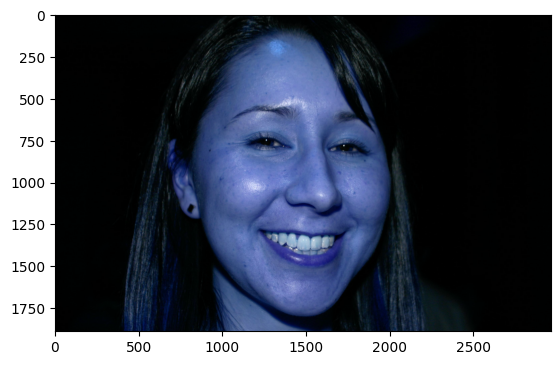

In [18]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir, "train"))):
    img = cv2.imread(os.path.join(image_dir,"train", image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

## Creating Text files for labels

Creating Dataframes from COCO annotations

In [24]:
# Creating a dataframe from COCO annotations

df = {
    'name': [],
    'label': [],
    'width': [],
    'height': [],
    'xmin': [],
    'ymin': [],
    'xmax': [],
    'ymax': []
}

# Load COCO annotation file
annotation_path = os.path.join(
    source_dir, "train", "_annotations.coco.json"
)

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

# Create dictionary to match image IDs with filenames
image_dict = {
    image['id']: image
    for image in coco_data['images']
}

# Read annotations and extract image and bounding box information
for idx, anno in enumerate(coco_data['annotations']):

    image = image_dict[anno['image_id']]

    filename = os.path.splitext(image['file_name'])[0]

    width = image['width']
    height = image['height']

    # Get class label
    category_id = anno['category_id']

    category_name = next(
        category['name']
        for category in coco_data['categories']
        if category['id'] == category_id
    )

    # Keep only Open and Closed classes
    if category_name.lower() not in ['open', 'closed']:
        continue

    label = category_name.capitalize()

    # COCO bounding box format: x, y, width, height
    x, y, box_width, box_height = anno['bbox']

    # Convert to xmin, ymin, xmax, ymax
    xmin = int(round(x))
    ymin = int(round(y))
    xmax = int(round(x + box_width))
    ymax = int(round(y + box_height))

    # Add information to dataframe dictionary
    df['name'].append(filename)
    df['label'].append(label)
    df['width'].append(width)
    df['height'].append(height)
    df['xmin'].append(xmin)
    df['ymin'].append(ymin)
    df['xmax'].append(xmax)
    df['ymax'].append(ymax)

# Convert dictionary into pandas dataframe
df = pd.DataFrame(df)

print("Dataframe created successfully")
print("Total annotations:", len(df))

df.head()

Dataframe created successfully
Total annotations: 101


,name,label,width,height,xmin,ymin,xmax,ymax
0,2344217511_1_jpg.rf.99TTci4QK7wUoqLOaVVS,Open,1230,856,405,400,686,480
1,2308489181_3_jpg.rf.8u5H033VAGojxBPifSYU,Open,939,938,349,350,583,401
2,3051765471_2_jpg.rf.1z6uTSM6UFpAQSfiaDx1,Open,2553,2501,0,1083,650,1276
3,3051765471_2_jpg.rf.1z6uTSM6UFpAQSfiaDx1,Open,2553,2501,1118,917,1636,1093
4,2385787737_1_jpg.rf.1GIYAOl53Z3TzweMhXMb,Open,2963,1889,1070,708,1888,860


Do the same for validation data labels.

In [28]:
# Creating a dataframe from COCO validation annotations

df2 = {
    'name': [],
    'label': [],
    'width': [],
    'height': [],
    'xmin': [],
    'ymin': [],
    'xmax': [],
    'ymax': []
}

# Load COCO validation annotation file
val_annotation_path = os.path.join(
    source_dir, "valid", "_annotations.coco.json"
)

with open(val_annotation_path, "r") as f:
    val_coco_data = json.load(f)

# Create dictionary to match image IDs with filenames
val_image_dict = {
    image['id']: image
    for image in val_coco_data['images']
}

# Create dictionary to match category IDs with class names
val_category_dict = {
    category['id']: category['name']
    for category in val_coco_data['categories']
}

# Read annotations and extract image and bounding box information
for idx, anno in enumerate(val_coco_data['annotations']):

    image = val_image_dict[anno['image_id']]

    filename = os.path.splitext(image['file_name'])[0]

    width = image['width']
    height = image['height']

    # Get class label
    category_id = anno['category_id']
    category_name = val_category_dict[category_id]

    # Keep only Open and Closed classes
    if category_name.lower() not in ['open', 'closed']:
        continue

    label = category_name.capitalize()

    # COCO bounding box format: x, y, width, height
    x, y, box_width, box_height = anno['bbox']

    # Convert to xmin, ymin, xmax, ymax
    xmin = int(round(x))
    ymin = int(round(y))
    xmax = int(round(x + box_width))
    ymax = int(round(y + box_height))

    # Add information to dataframe dictionary
    df2['name'].append(filename)
    df2['label'].append(label)
    df2['width'].append(width)
    df2['height'].append(height)
    df2['xmin'].append(xmin)
    df2['ymin'].append(ymin)
    df2['xmax'].append(xmax)
    df2['ymax'].append(ymax)

# Convert dictionaries into pandas dataframes
train_df = pd.DataFrame(df)
val_df = pd.DataFrame(df2)

print("Validation dataframe created successfully")
print("Total validation annotations:", len(val_df))

val_df.head()


Validation dataframe created successfully
Total validation annotations: 12


,name,label,width,height,xmin,ymin,xmax,ymax
0,2326138430_1_jpg.rf.0WLfxz5siMnKOtUg3SZR,Open,1550,1561,112,253,480,329
1,2326138430_1_jpg.rf.0WLfxz5siMnKOtUg3SZR,Open,1550,1561,599,608,969,686
2,2218537300_1_jpg.rf.Yb5SkSEtXoSyUVxXOM0k,Open,768,1024,388,377,523,441
3,2218537300_1_jpg.rf.Yb5SkSEtXoSyUVxXOM0k,Closed,768,1024,172,397,316,464
4,3038732539_1_jpg.rf.D3i6g7U4n3tKMCnLfsX9,Open,1390,1390,481,505,776,591


In [29]:
# Creating YOLO text files for each validation image

# Create directory to store validation text labels
val_txt_dir = os.path.join(source_dir, "valid", "labels")
os.makedirs(val_txt_dir, exist_ok=True)

# Map class names to YOLO class IDs
class_map = {
    'Open': 0,
    'Closed': 1
}

# Convert bounding boxes and create individual text files
for filename in val_df['name'].unique():

    image_df = val_df[val_df['name'] == filename]

    txt_path = os.path.join(val_txt_dir, filename + ".txt")

    with open(txt_path, "w") as f:

        for _, row in image_df.iterrows():

            # Get class ID
            class_id = class_map[row['label']]

            # Normalize bounding box coordinates
            x_center = ((row['xmin'] + row['xmax']) / 2) / row['width']
            y_center = ((row['ymin'] + row['ymax']) / 2) / row['height']

            box_width = (row['xmax'] - row['xmin']) / row['width']
            box_height = (row['ymax'] - row['ymin']) / row['height']

            # Write YOLO format annotation
            f.write(
                f"{class_id} {x_center} {y_center} "
                f"{box_width} {box_height}\n"
            )

print("Validation YOLO text files created successfully")
print("Total validation text files:", len(os.listdir(val_txt_dir)))


Validation YOLO text files created successfully
Total validation text files: 9


### Visualize with bounding box

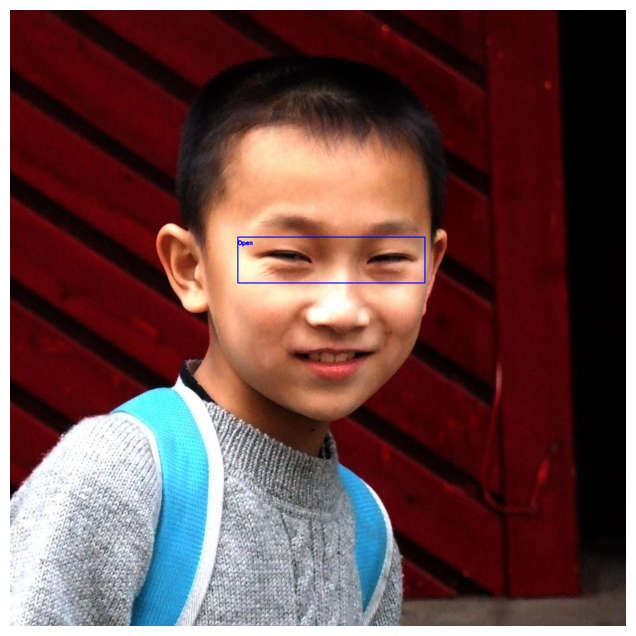

In [30]:

# Visualizing an image from the training dataset with bounding boxes

import cv2
import matplotlib.pyplot as plt
import glob

# Select an image to visualize
index = 10

# Get image filename from training dataframe
filename = train_df.iloc[index]['name']

# Find the image file
image_paths = (
    glob.glob(os.path.join(source_dir, "train", filename + ".*")) +
    glob.glob(os.path.join(source_dir, "train", "images", filename + ".*"))
)

if not image_paths:
    raise FileNotFoundError(f"Could not find image: {filename}")

image_path = image_paths[0]

# Load image
image = cv2.imread(image_path)

# Get all annotations belonging to this image
image_annotations = train_df[train_df['name'] == filename]

# Draw bounding boxes and labels
for _, row in image_annotations.iterrows():

    cv2.rectangle(
        image,
        (int(row['xmin']), int(row['ymin'])),
        (int(row['xmax']), int(row['ymax'])),
        (255, 0, 0),
        2
    )

    label = row['label']

    cv2.putText(
        image,
        label,
        (int(row['xmin']), int(row['ymin']) + 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

# Convert BGR to RGB for Matplotlib
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display image
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis('off')
plt.show()


### Testing

In [ ]:
!yolo predict model=yolov8n.pt source='https://ultralytics.com/images/zidane.jpg' save=True

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

Found https://ultralytics.com/images/zidane.jpg locally at zidane.jpg
image 1/1 /content/drive/MyDrive/Colab Notebooks/zidane.jpg: 384x640 2 persons, 1 tie, 9.0ms
Speed: 89.7ms preprocess, 9.0ms inference, 36.5ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/Colab Notebooks/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


## Prepared Training

In [ ]:
model = YOLO('yolov8s.pt')

# replace with actual location of data.yaml file
# adjust hyperparameters after the baseline run
results = model.train(
    data='/content/drive/MyDrive/blink-detector/dataset/data.yaml',
    epochs=50,
    imgsz=640,
    batch=8,
    patience=10,
    project='/content/drive/MyDrive/blink-detector/runs',
    name='blink_detection'
)

## Validate model accuracy

In [ ]:
metrics = model.val()

### Test on images



In [ ]:
model = YOLO("/content/runs/detect/blink_detection/weights/best.pt")

results = model.predict(
    source="/content/drive/MyDrive/blink-detector/test_image.jpg",
    conf=0.25,
    save=True,
    show_labels=True
)